# 01 — EDA: TikTok Video Engagement 200k

**Goal:** understand the data, choose a target, check that creators have enough videos for per-creator models, and test whether success factors differ between creators.

**Input:** dataset `lingbow/tiktok-video-engagement-200k` — three tables: `videos`, `engagement_daily`, `creator_daily`.

**Key results (details in the Conclusions at the end):**
- 209,543 videos from 1,872 creators, posted 24 Jun – 9 Nov 2024. The median creator has 69 videos, so per-creator models are feasible.
- Target: `log(1 + views)` about 30 days after posting. Raw views are far too skewed.
- The creator alone explains **74%** of the variance in log views.
- Global correlations are mostly driven by differences *between* creators. Inside creators, feature effects vary more than noise would explain — this supports personalization.

## 0. Setup

Clone the repo (only if it is not there yet), install the dependencies and our package `creator_analytics`. The notebook imports code from `src/` instead of copying it.

**Colab notes:**
- After the first install, restart the session (*Runtime → Restart session*) and run again: the pinned numpy/pandas versions are loaded only after a restart.
- The pip "dependency conflicts" message is about Colab's own packages and can be ignored.
- We don't use `%autoreload`: it is broken in Colab's IPython on Python 3.13.

In [1]:
import os, sys
from google.colab import userdata

REPO = "Personalized_anaysis_of_social_media"
REPO_DIR = f"/content/{REPO}"

if not os.path.exists(REPO_DIR):
    token = userdata.get("GITHUB_TOKEN")
    !git clone -q https://{token}@github.com/Shopska/{REPO}.git {REPO_DIR}

%cd {REPO_DIR}
!git pull -q
!pip install -q -r requirements.txt
!pip install -q -e .
sys.path.insert(0, f"{REPO_DIR}/src")

/content/Personalized_anaysis_of_social_media
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for creator-analytics (pyproject.toml) ... done


In [2]:
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from creator_analytics.config import load_config
from creator_analytics.data import creator_video_counts, filter_creators
from creator_analytics.utils import set_seed

cfg = load_config("config/default.yaml")
set_seed(cfg["seed"])
AUTHOR = cfg["data"]["author_column"]
MIN_VIDEOS = cfg["data"]["min_videos_per_creator"]

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True

## 1. Load the data

The dataset has three tables:
- `videos` — content and metadata (one row per video);
- `engagement_daily` — cumulative views/likes/comments for each day 0–30 after posting;
- `creator_daily` — account stats (followers etc.) by day.

Files are cached on Google Drive, because `/content` is wiped after every session. If a file is not on Drive yet, it is downloaded once from Hugging Face.

**Result:** 209,543 videos, 6,068,955 daily engagement rows, 278,433 creator-day rows.

In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DATA = Path("/content/drive/MyDrive/creator_analytics/data")
RAW = Path("data/raw")
DRIVE_DATA.mkdir(parents=True, exist_ok=True)
RAW.mkdir(parents=True, exist_ok=True)

def get_table(name):
    local = RAW / f"{name}.parquet"
    remote = DRIVE_DATA / f"{name}.parquet"
    if not local.exists():
        if not remote.exists():
            from datasets import load_dataset
            load_dataset(cfg["data"]["hf_repo"], name, split="train").to_pandas().to_parquet(remote, index=False)
        shutil.copy(remote, local)
    return pd.read_parquet(local)

Mounted at /content/drive


In [4]:
videos = get_table("videos")
eng = get_table("engagement_daily")
creators = get_table("creator_daily")

for name, d in [("videos", videos), ("engagement_daily", eng), ("creator_daily", creators)]:
    print(f"{name:18s} {d.shape[0]:>10,} рядків {d.shape[1]:>4} колонок")

README.md:   0%|          | 0.00/9.26k [00:00<?, ?B/s]

videos.parquet: reconstructing file:   0%|          |  0.00B /  107MB            

videos.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/209543 [00:00<?, ? examples/s]

engagement_daily.parquet: reconstructing file:   0%|          |  0.00B / 26.3MB            

...

Generating train split:   0%|          | 0/6068955 [00:00<?, ? examples/s]

creator_daily.parquet: reconstructing file:   0%|          |  0.00B / 2.32MB            

creator_daily.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/278433 [00:00<?, ? examples/s]

videos                209,543 рядків   33 колонок
engagement_daily    6,068,955 рядків   10 колонок
creator_daily         278,433 рядків    7 колонок


## 2. Table structure and links

We check column types, that `video_id` is unique, and that every video has engagement and creator data.

**Result:** no duplicate videos; 100% of videos have engagement data and 100% of creators have account stats. Videos were posted between **24 Jun and 9 Nov 2024**.

In [5]:
videos.info()

<class 'pandas.DataFrame'>
RangeIndex: 209543 entries, 0 to 209542
Data columns (total 33 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   video_id             209543 non-null  str    
 1   author_id            209543 non-null  str    
 2   create_time          209543 non-null  str    
 3   create_date          209543 non-null  str    
 4   duration             209543 non-null  float64
 5   ratio                209543 non-null  str    
 6   desc_language        209543 non-null  str    
 7   is_english           209543 non-null  int64  
 8   desc                 190437 non-null  str    
 9   sticker_text         98833 non-null   str    
 10  hashtags             209543 non-null  object 
 11  created_by_ai        209542 non-null  float64
 12  is_ads               209543 non-null  str    
 13  music_selected_from  206770 non-null  str    
 14  music_album          47033 non-null   str    
 15  music_author         209183 

In [6]:
display(videos.head(3))
display(eng.head(3))
display(creators.head(3))

,video_id,author_id,create_time,create_date,duration,ratio,desc_language,is_english,desc,sticker_text,hashtags,created_by_ai,is_ads,music_selected_from,music_album,music_author,music_owner_id,music_id,music_title,transcript,word_count,emoji_count,question_count,hashtag_count,speaking_rate,gpt_summary,topic,anger,joy,surprise,sadness,disgust,fear
0,7386493327656504607,6958316329012003846,2024-06-30 21:46:54,2024-06-30,20.067,540p,un,0,#fallowme #foryoupage #fyp #fypp #goodengery #...,NaN,"[{'hashtag_id': '13497', 'hashtag_name': 'good...",0.0,0,edit_page_list,Nasty,Tinashe,NaN,7353374941268363265,Nasty,NaN,0.0,0.0,0.0,14.0,0.000000,"In this short video, the creator is seen in a ...",Lifestyle,0.007287,0.427565,0.004642,0.011638,0.154876,0.001623
1,7386314758808522014,6958316329012003846,2024-06-30 10:14:14,2024-06-30,83.100,540p,un,0,#fyp #foryoupage #fallowme #TikTokShop #newdro...,new drop coming,"[{'hashtag_id': '152178', 'hashtag_name': 'sho...",0.0,0,edit_page_list,Nasty,Tinashe,NaN,7353374941268363265,Nasty,NaN,3.0,0.0,0.0,7.0,0.000000,The video showcases a vibrant collection of un...,Beauty_Fashion,0.003728,0.850722,0.009022,0.003120,0.008401,0.000587
2,7387143945744141599,6958316329012003846,2024-07-02 15:51:42,2024-07-02,26.634,540p,un,0,#goodengery #packages #sample #mail #fyppppppp...,NaN,"[{'hashtag_id': '1649139584636934', 'hashtag_n...",0.0,0,original,NaN,MommaTata,6958316329012003846,7387144018116758303,original sound - mommatata420,when you go to the mail thinking that you only...,0.0,0.0,0.0,5.0,5.894721,"In this short video, the creator humorously re...",Life_hacks_Personal_growth,0.318762,0.197186,0.013447,0.051367,0.118099,0.000834


,video_id,date,days_since_post,play_count,like_count,comment_count,share_count,collect_count,download_count,whatsapp_share_count
0,7381889522268654890,2024-06-25,0,1737,26,0,0,0,0,0
1,7381889522268654890,2024-06-26,1,1772,28,0,0,0,0,0
2,7381889522268654890,2024-06-27,2,1778,28,0,0,0,0,0


,author_id,date,follower_count,following_count,total_favorited,video_count,enterprise_verified
0,10245051,2024-06-27,1704.0,1039.0,75987,83.0,NaN
1,10245051,2024-06-28,1704.0,1039.0,76018,83.0,NaN
2,10245051,2024-06-29,1704.0,1039.0,76024,83.0,NaN


In [7]:
videos["create_date"] = pd.to_datetime(videos["create_date"]).astype("datetime64[ns]")

print("Дублікати video_id у videos:", videos["video_id"].duplicated().sum())
print("Частка відео з даними engagement:", round(videos["video_id"].isin(eng["video_id"]).mean(), 3))
print("Частка креаторів з даними creator_daily:", round(videos[AUTHOR].drop_duplicates().isin(creators["author_id"]).mean(), 3))
print("Період публікацій:", videos["create_date"].min().date(), "—", videos["create_date"].max().date())

Дублікати video_id у videos: 0
Частка відео з даними engagement: 1.0
Частка креаторів з даними creator_daily: 1.0
Період публікацій: 2024-06-24 — 2024-11-09


## 3. Missing values

Shows which features we can rely on.

**Result:**
- `transcript` is missing for 60% of videos, `sticker_text` for 53%. Here "missing" usually means "no speech" / "no text on screen", so it is information, not an error.
- The text statistics (`word_count`, `emoji_count`, `question_count`, `hashtag_count`, `speaking_rate`) are missing **together** for 38% of videos. Analyses with these features use only the other 62%.
- Emotion scores are missing for only 0.5% of videos.
- `music_album` (78% missing) is not useful.

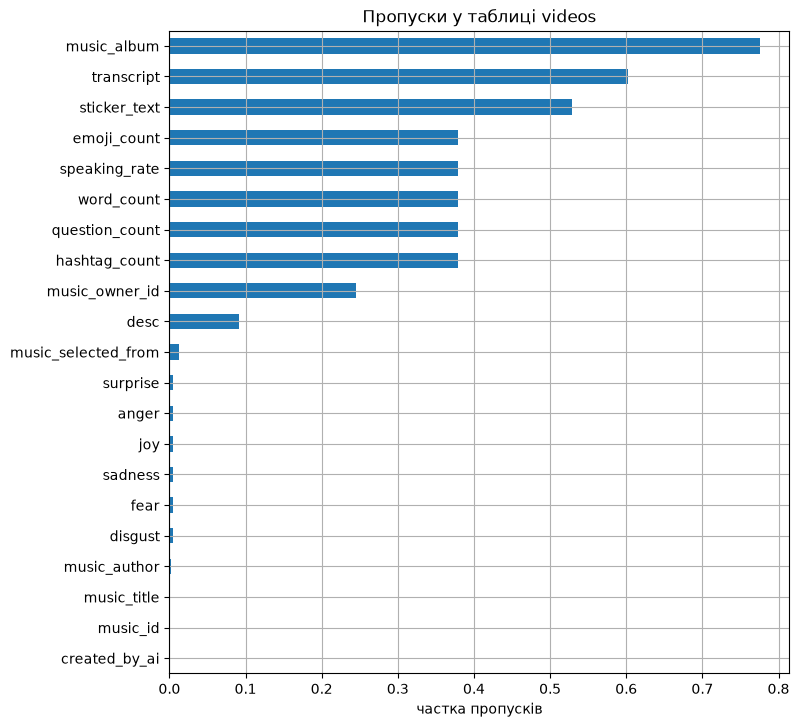

In [8]:
missing = videos.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

if len(missing):
    ax = missing.plot.barh(figsize=(8, 0.35 * len(missing) + 1))
    ax.invert_yaxis()
    ax.set_xlabel("частка пропусків")
    ax.set_title("Пропуски у таблиці videos")
    plt.show()
else:
    print("Пропусків немає")

## 4. How many videos does each creator have?

The main risk from our proposal: a per-creator model trained on a handful of videos learns noise. Both axes are logarithmic because the distribution has a long tail. The threshold table helps choose `min_videos_per_creator` in `config/default.yaml` (dashed line = current value, 30).

**Result:**
- Every creator has at least 5 videos (the dataset authors seem to have filtered this). Median 69, mean 112, maximum 2,218.
- A few creators have 1,000+ videos — most likely media accounts that post several times a day.
- With a threshold of **30** we keep **1,439 creators and 96% of videos**; with 50 — 1,143 creators and 91%. So the threshold of 30 costs almost nothing.
- Note: the biggest creators take a large share of the data, so they can dominate a global model.

Унікальних креаторів: 1,872


,відео на креатора
count,1872.0
mean,111.9
std,142.9
min,5.0
25%,32.0
50%,69.0
75%,137.0
90%,252.0
99%,686.0
max,2218.0


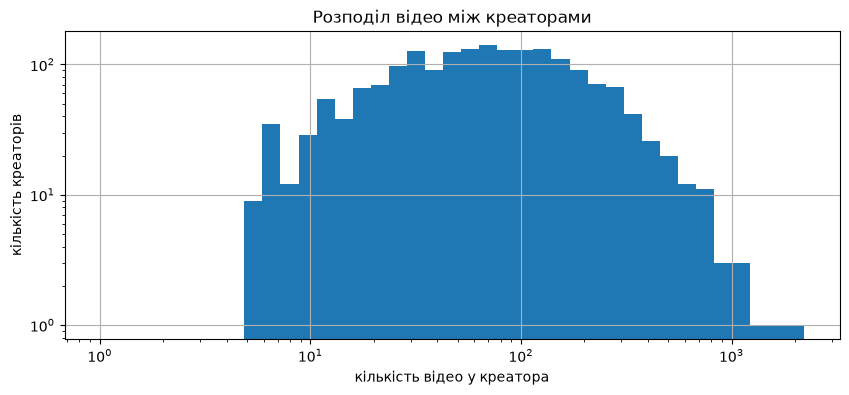

In [9]:
counts = creator_video_counts(videos, AUTHOR)
print(f"Унікальних креаторів: {counts.size:,}")
display(counts.describe(percentiles=[.25, .5, .75, .9, .99]).round(1).to_frame("відео на креатора"))

fig, ax = plt.subplots()
ax.hist(counts, bins=np.logspace(0, np.log10(counts.max() + 1), 40))
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("кількість відео у креатора")
ax.set_ylabel("кількість креаторів")
ax.set_title("Розподіл відео між креаторами")
plt.show()

,креаторів,відео,частка відео
мін. відео,,,
5,1872,209543,1.000
10,1802,209051,0.998
20,1629,206519,0.986
30,1439,201832,0.963
50,1143,190260,0.908
75,871,173383,0.827
100,681,156867,0.749


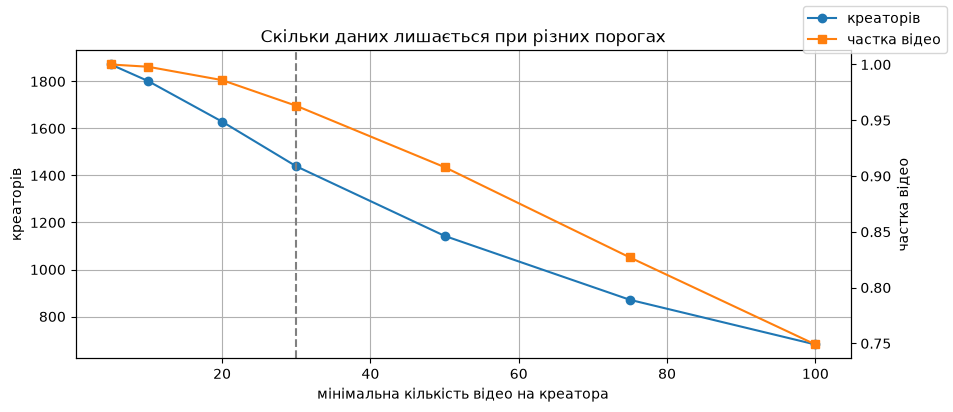

In [10]:
thresholds = [5, 10, 20, 30, 50, 75, 100]
kept = pd.DataFrame(
    {
        "креаторів": [(counts >= t).sum() for t in thresholds],
        "відео": [counts[counts >= t].sum() for t in thresholds],
    },
    index=pd.Index(thresholds, name="мін. відео"),
)
kept["частка відео"] = (kept["відео"] / counts.sum()).round(3)
display(kept)

fig, ax1 = plt.subplots()
ax1.plot(kept.index, kept["креаторів"], marker="o", label="креаторів")
ax1.set_xlabel("мінімальна кількість відео на креатора")
ax1.set_ylabel("креаторів")
ax1.axvline(MIN_VIDEOS, ls="--", color="grey")
ax2 = ax1.twinx()
ax2.plot(kept.index, kept["частка відео"], marker="s", color="tab:orange", label="частка відео")
ax2.set_ylabel("частка відео")
ax2.grid(False)
fig.legend(loc="upper right")
ax1.set_title("Скільки даних лишається при різних порогах")
plt.show()

## 5. Target: how views accumulate

The `videos` table has no performance metrics. Views, likes and comments are in `engagement_daily` as **cumulative** counters for each day after posting.

- **Plot 1:** for which share of videos we have data on each day.
- **Plot 2:** what share of its final (day-30) views a video already has on day *d*.

**Result:**
- Days 1–29 are covered for 92–100% of videos, but **day 30 only for ~35%** (and day 0 for ~75%).
- Views come very fast: a typical video has ~68% of its views after day 1, ~86% after day 5 and ~92% after day 10. After day ~20 the curve is almost flat.

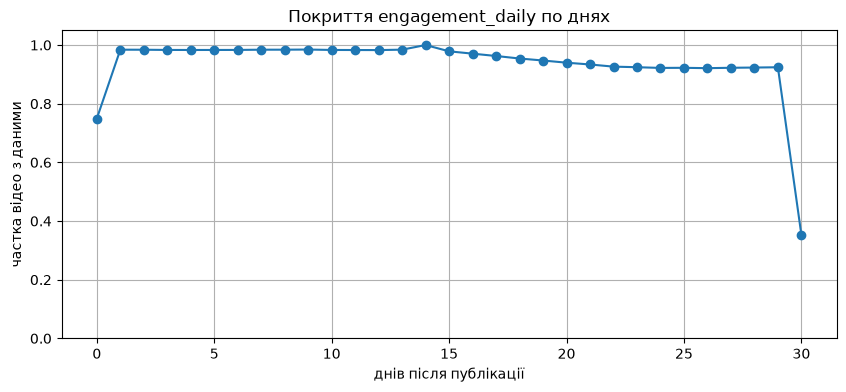

In [11]:
eng["days_since_post"] = eng["days_since_post"].astype(int)
eng_valid = eng.dropna(subset=["play_count"])
n_eng_videos = eng_valid["video_id"].nunique()

coverage = eng_valid.groupby("days_since_post")["video_id"].nunique() / n_eng_videos
ax = coverage.plot(marker="o")
ax.set_ylim(0, 1.05)
ax.set_xlabel("днів після публікації")
ax.set_ylabel("частка відео з даними")
ax.set_title("Покриття engagement_daily по днях")
plt.show()

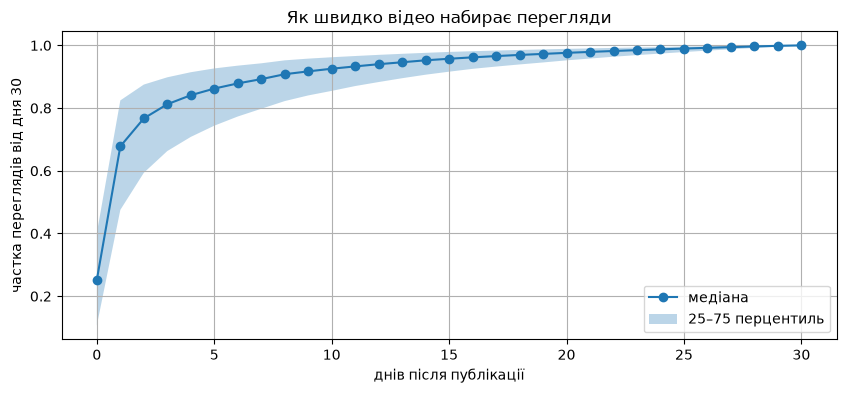

In [12]:
MAX_DAY = int(eng_valid["days_since_post"].max())
final_ids = eng_valid.loc[eng_valid["days_since_post"] == MAX_DAY, "video_id"].drop_duplicates()
sample_ids = final_ids.sample(min(20000, len(final_ids)), random_state=cfg["seed"])

curve = eng_valid[eng_valid["video_id"].isin(sample_ids)].pivot_table(
    index="video_id", columns="days_since_post", values="play_count"
)
share = curve.div(curve[MAX_DAY], axis=0).replace([np.inf, -np.inf], np.nan)
q = share.quantile([0.25, 0.5, 0.75])

fig, ax = plt.subplots()
ax.plot(q.columns, q.loc[0.5], marker="o", label="медіана")
ax.fill_between(q.columns, q.loc[0.25], q.loc[0.75], alpha=0.3, label="25–75 перцентиль")
ax.set_xlabel("днів після публікації")
ax.set_ylabel(f"частка переглядів від дня {MAX_DAY}")
ax.set_title("Як швидко відео набирає перегляди")
ax.legend()
plt.show()

### Build the target

For each video we take the last observation up to `TARGET_DAY = 30`. Videos observed for less than `MIN_OBSERVED_DAY = 7` days would be dropped, so that we don't compare videos of different "age".

We also compute the **engagement rate** = (likes + comments + shares) / views. It depends less on the audience size. Here we also add a few helper columns used later (hour, weekday, has transcript, dominant emotion).

**Result:** all 209,543 videos keep a target. For 93% of them it is measured on day 29–30, the rest mostly on days 23–28. Because views barely grow after day 20 (plot above), this difference is negligible.

In [14]:
TARGET_DAY = 30
MIN_OBSERVED_DAY = 7
METRICS = ["play_count", "like_count", "comment_count", "share_count", "collect_count"]

last = (
    eng_valid[eng_valid["days_since_post"] <= TARGET_DAY]
    .sort_values(["video_id", "days_since_post"])
    .groupby("video_id")
    .tail(1)[["video_id", "days_since_post"] + METRICS]
    .rename(columns={"days_since_post": "observed_day"})
)
display(last["observed_day"].value_counts(normalize=True).sort_index().tail(8).round(3).to_frame("частка відео"))

df = videos.merge(last, on="video_id", how="inner")
df = df[df["observed_day"] >= MIN_OBSERVED_DAY].copy()

df["log_views"] = np.log1p(df["play_count"])
views = df["play_count"].replace(0, np.nan)
for m in ["like", "comment", "share", "collect"]:
    df[f"{m}_rate"] = df[f"{m}_count"] / views
df["engagement_rate"] = (df["like_count"] + df["comment_count"] + df["share_count"]) / views

EMOTIONS = ["anger", "joy", "surprise", "sadness", "disgust", "fear"]
create_time = pd.to_datetime(df["create_time"])
df["hour"] = create_time.dt.hour
df["weekday"] = create_time.dt.dayofweek
df["has_transcript"] = df["transcript"].notna().astype(int)
df["has_sticker_text"] = df["sticker_text"].notna().astype(int)
has_emotions = df[EMOTIONS].notna().any(axis=1)
df["dominant_emotion"] = df[EMOTIONS].fillna(-1).idxmax(axis=1).where(has_emotions)
print(f"Відео без emotion scores: {(~has_emotions).mean():.1%}")

print(f"Відео з ціллю: {len(df):,} з {len(videos):,}")

,частка відео
observed_day,
23,0.009
24,0.008
25,0.008
26,0.008
27,0.007
28,0.016
29,0.580
30,0.353


Відео без emotion scores: 0.5%
Відео з ціллю: 209,543 з 209,543


## 6. Target distribution

**Result:**
- **Raw views** are extremely skewed: median **641**, 90th percentile ~20k, 99th ~579k, maximum **44 million**. With raw views, RMSE would be driven by a few viral videos.
- **`log(1 + views)`** has a normal scale: a sharp peak around 6–6.5 (≈ 400–650 views) and a long right tail. This will be our **main regression target**.
- **Engagement rate**: median ~7% (likes alone ~6%), long right tail. The spike at the right edge of the plot is an artifact of clipping at the 99th percentile. A few values above 1 are data noise (e.g., more likes than views).
- The two targets measure different things: their correlation is only −0.11 (see section 8).

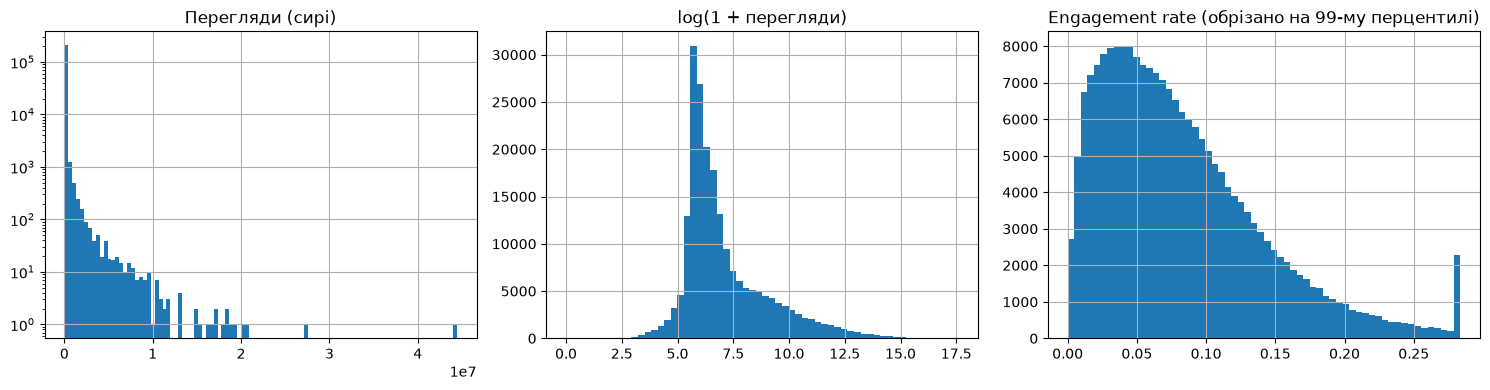

,count,mean,std,min,50%,90%,99%,max
play_count,209543.0,31590.2322,326930.7306,0.0,641.0000,20225.0000,579184.6400,4.444290e+07
log_views,209543.0,7.0931,1.9163,0.0,6.4646,9.9147,13.2694,1.760970e+01
like_rate,209502.0,0.0732,0.0519,0.0,0.0629,0.1433,0.2345,1.000000e+00
comment_rate,209502.0,0.0075,0.0163,0.0,0.0024,0.0191,0.0759,1.034600e+00
share_rate,209502.0,0.0025,0.0091,0.0,0.0000,0.0060,0.0317,9.000000e-01
engagement_rate,209502.0,0.0832,0.0622,0.0,0.0702,0.1627,0.2837,1.450000e+00


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["play_count"], bins=100)
axes[0].set_yscale("log")
axes[0].set_title("Перегляди (сирі)")
axes[1].hist(df["log_views"], bins=60)
axes[1].set_title("log(1 + перегляди)")
er = df["engagement_rate"].dropna()
axes[2].hist(er.clip(upper=er.quantile(0.99)), bins=60)
axes[2].set_title("Engagement rate (обрізано на 99-му перцентилі)")
plt.tight_layout()
plt.show()

display(df[["play_count", "log_views", "like_rate", "comment_rate", "share_rate", "engagement_rate"]]
        .describe(percentiles=[.5, .9, .99]).T.round(4))

## 7. How much does the creator alone explain?

We compute the share of the target's variance explained only by `author_id` (between-creator variance / total variance). If it is high, a global model mostly learns "who is the author", not "what is in the content".

That's why for per-creator analysis we also create a **relative target** `rel_log_views` = how much better or worse a video is than the creator's typical video. Creators are anonymized (C1, C2, …), as the data card requires.

**Result:**
- After the ≥30 videos filter: 1,439 creators, 201,832 videos.
- The creator explains **74.3%** of the variance in log views and **51.4%** in engagement rate.
- The boxplot shows the same: creators differ a lot in their typical level (medians from ~4.5 to ~11), and much less within themselves.

In [17]:
dfc = filter_creators(df, AUTHOR, MIN_VIDEOS)
dfc["rel_log_views"] = dfc["log_views"] - dfc.groupby(AUTHOR)["log_views"].transform("median")
print(f"Після фільтра ≥{MIN_VIDEOS} відео: {dfc[AUTHOR].nunique():,} креаторів, {len(dfc):,} відео")

def creator_share_of_variance(d, col):
    d = d.dropna(subset=[col])
    total = ((d[col] - d[col].mean()) ** 2).sum()
    within = ((d[col] - d.groupby(AUTHOR)[col].transform("mean")) ** 2).sum()
    return 1 - within / total

for col in ["log_views", "engagement_rate"]:
    print(f"{col}: креатор пояснює {creator_share_of_variance(dfc, col):.1%} дисперсії")

Після фільтра ≥30 відео: 1,439 креаторів, 201,832 відео
log_views: креатор пояснює 74.3% дисперсії
engagement_rate: креатор пояснює 51.4% дисперсії


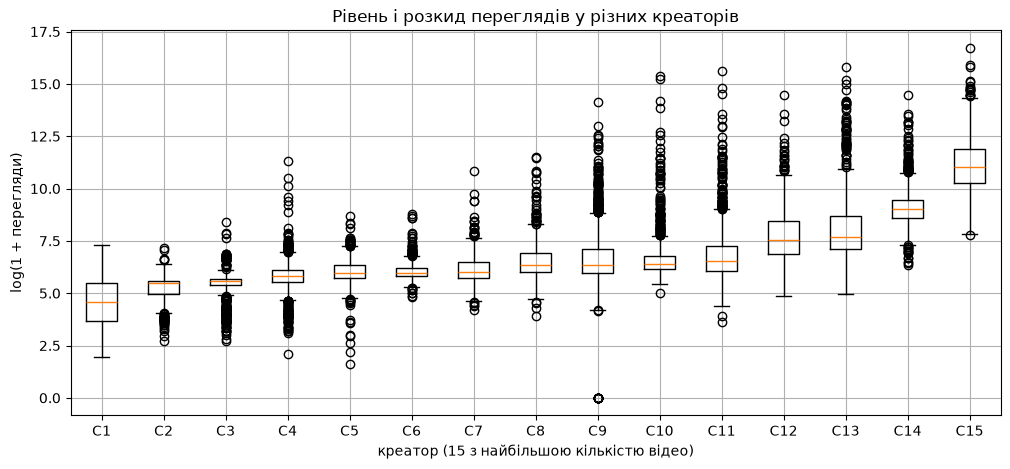

In [18]:
top = dfc[AUTHOR].value_counts().head(15).index
order = dfc[dfc[AUTHOR].isin(top)].groupby(AUTHOR)["log_views"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([dfc.loc[dfc[AUTHOR] == a, "log_views"] for a in order],
           tick_labels=[f"C{i + 1}" for i in range(len(order))])
ax.set_xlabel("креатор (15 з найбільшою кількістю відео)")
ax.set_ylabel("log(1 + перегляди)")
ax.set_title("Рівень і розкид переглядів у різних креаторів")
plt.show()

## 8. Content features vs views (global view)

Which features are related to views at all: topic, music source (`music_selected_from` — our proxy for the editing template), duration, text features, emotions, posting time. We use medians and Spearman correlation, because the data are skewed and relations may be non-linear. These are hints for Feature Engineering, not proof of cause.

**Result:**
- **Topic:** medians differ only a little (Sports_Fitness is the highest, Life_hacks the lowest).
- **Music source:** `edit_page_recent` stands out (median ~7.8 vs ~6.1–6.6 for most others), `duet` is the lowest.
- **Correlations with log views:** strongest for `word_count` (0.48) and `question_count` (0.31); emotions are close to 0. `speaking_rate` and `has_transcript` are almost the same feature (0.95), and emotions are strongly correlated with each other (e.g., joy vs fear −0.82).
- **Duration:** 60–90 s videos have the highest median.
- **Posting hour:** afternoon (15–18 h) is better than night; **weekday** makes almost no difference.

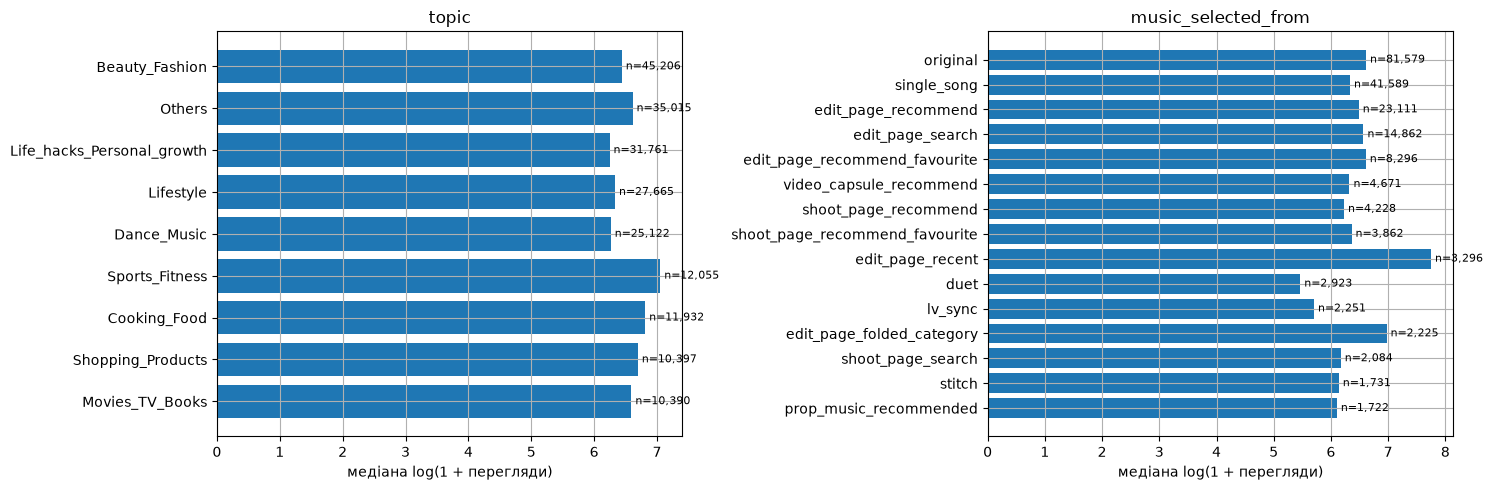

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ["topic", "music_selected_from"]):
    g = df.groupby(col)["log_views"].agg(["size", "median"]).sort_values("size", ascending=False).head(15)
    ax.barh(g.index.astype(str), g["median"])
    for i, (n, m) in enumerate(zip(g["size"], g["median"])):
        ax.text(m, i, f" n={n:,}", va="center", fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel("медіана log(1 + перегляди)")
    ax.set_title(col)
plt.tight_layout()
plt.show()

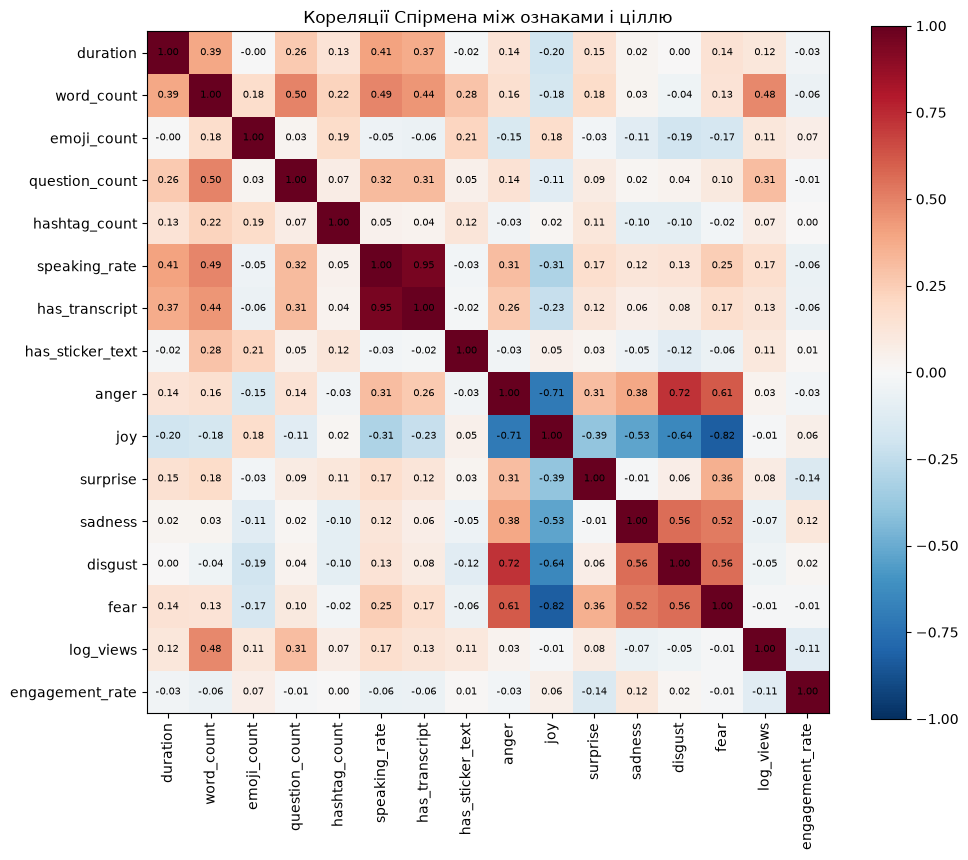

In [20]:
NUMERIC = ["duration", "word_count", "emoji_count", "question_count", "hashtag_count",
           "speaking_rate", "has_transcript", "has_sticker_text"] + EMOTIONS

corr = df[NUMERIC + ["log_views", "engagement_rate"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Кореляції Спірмена між ознаками і ціллю")
plt.show()

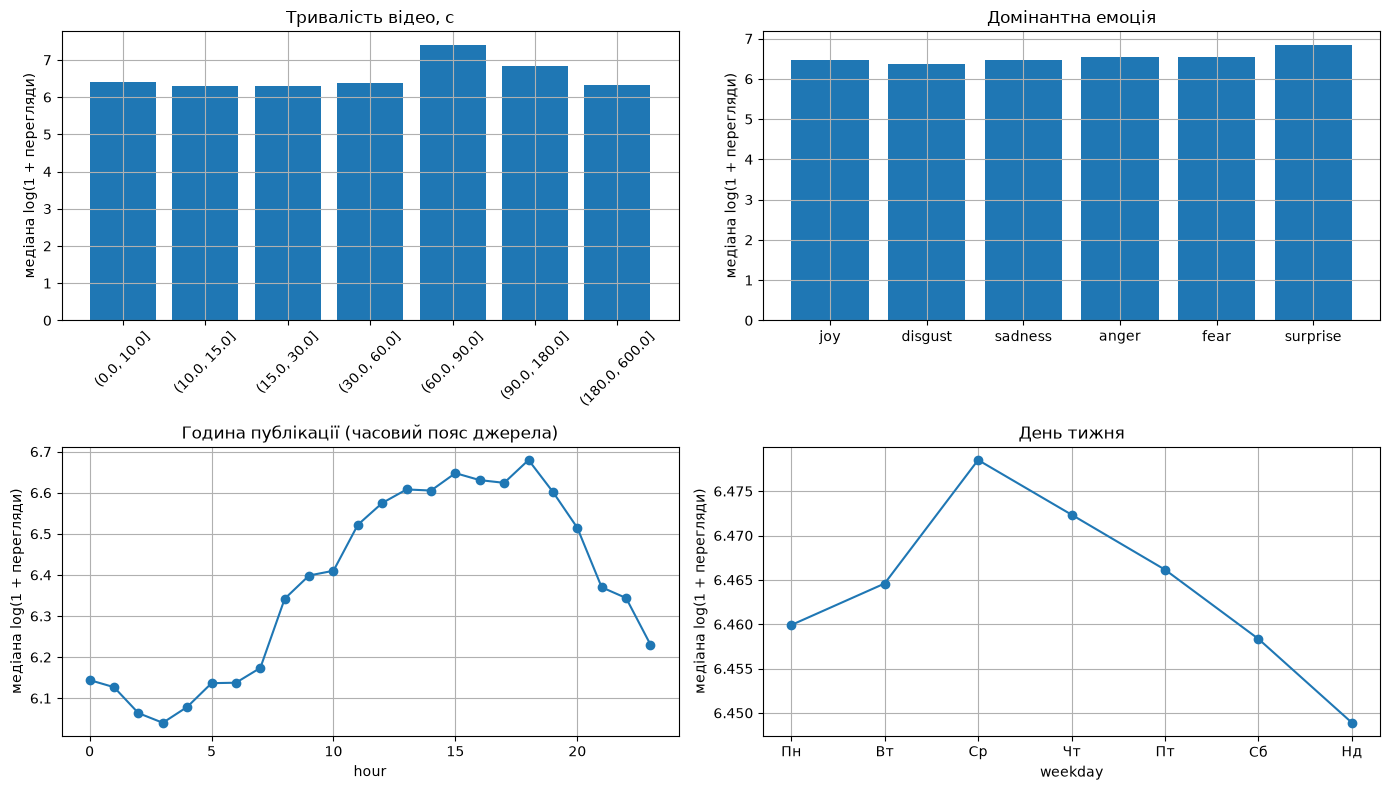

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

bins = [0, 10, 15, 30, 60, 90, 180, 600, np.inf]
g = df.groupby(pd.cut(df["duration"], bins), observed=True)["log_views"].median()
axes[0, 0].bar(g.index.astype(str), g.values)
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].set_title("Тривалість відео, с")

g = df.groupby("dominant_emotion")["log_views"].agg(["median", "size"]).sort_values("size", ascending=False)
axes[0, 1].bar(g.index, g["median"])
axes[0, 1].set_title("Домінантна емоція")

df.groupby("hour")["log_views"].median().plot(ax=axes[1, 0], marker="o")
axes[1, 0].set_title("Година публікації (часовий пояс джерела)")

df.groupby("weekday")["log_views"].median().plot(ax=axes[1, 1], marker="o")
axes[1, 1].set_xticks(range(7), ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"])
axes[1, 1].set_title("День тижня")

for ax in axes.flat:
    ax.set_ylabel("медіана log(1 + перегляди)")
plt.tight_layout()
plt.show()

## 9. Are success factors the same for all creators? (key hypothesis test)

For each creator separately we compute the correlation of a feature with log views and compare it to the global correlation (red diamond on the plot).

With 30–300 videos per creator, correlations are noisy anyway. So we build a **null distribution**: shuffle views within each creator and compute the same thing. If the real spread (`std_real`) is clearly bigger than the noise spread (`std_null`), the differences between creators are real.

**Result:**
- For **all 14 features**, `std_real` > `std_null` (ratio 1.24–1.60; highest for `word_count` 1.60 and `duration` 1.59). Feature effects really differ between creators.
- **Global correlations are inflated by differences between creators:** `word_count` is 0.48 globally but only 0.16 for a typical creator; `question_count` 0.31 vs 0.09.
- **`duration`:** globally +0.12, but for **54%** of creators the relation has the opposite sign. A global explanation ("longer is better") would be wrong for half of them.
- Effects inside a creator are modest (typical |ρ| below ~0.2). Whether personalization also improves *accuracy* will be shown by the model comparison.

The plot shows 9 of the 14 features for readability; the full table is above.

In [26]:
FEATS = ["duration", "word_count", "emoji_count", "question_count", "hashtag_count",
         "speaking_rate", "has_transcript", "has_sticker_text"] + EMOTIONS

rng = np.random.default_rng(cfg["seed"])
dfc["log_views_shuffled"] = dfc.groupby(AUTHOR)["log_views"].transform(lambda s: rng.permutation(s.to_numpy()))

def per_creator_corr(d, feat, target):
    return d.groupby(AUTHOR)[[feat, target]].apply(
        lambda g: g[feat].corr(g[target], method="spearman")
    ).dropna()

real, rows = {}, []
for f in FEATS:
    real[f] = per_creator_corr(dfc, f, "log_views")
    null = per_creator_corr(dfc, f, "log_views_shuffled")
    glob = dfc[f].corr(dfc["log_views"], method="spearman")
    rows.append({
        "ознака": f,
        "глобальна": glob,
        "медіана per-creator": real[f].median(),
        "std_real": real[f].std(),
        "std_null": null.std(),
        "частка з протилежним знаком": (np.sign(real[f]) != np.sign(glob)).mean(),
    })

summary = pd.DataFrame(rows).set_index("ознака").round(3)
display(summary)

/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1673: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/cor

,глобальна,медіана per-creator,std_real,std_null,частка з протилежним знаком
ознака,,,,,
duration,0.117,-0.018,0.178,0.112,0.543
word_count,0.481,0.156,0.232,0.145,0.238
emoji_count,0.116,0.017,0.176,0.143,0.461
question_count,0.310,0.090,0.187,0.135,0.300
hashtag_count,0.073,0.059,0.205,0.149,0.386
speaking_rate,0.169,0.030,0.192,0.146,0.436
has_transcript,0.126,0.028,0.163,0.113,0.451
has_sticker_text,0.106,0.077,0.168,0.118,0.313
anger,0.033,0.035,0.139,0.112,0.377


In [31]:
summary["std_real / std_null"] = (summary["std_real"] / summary["std_null"]).round(2)
display(summary.sort_values("std_real / std_null", ascending=False))

,глобальна,медіана per-creator,std_real,std_null,частка з протилежним знаком,std_real / std_null
ознака,,,,,,
word_count,0.481,0.156,0.232,0.145,0.238,1.60
duration,0.117,-0.018,0.178,0.112,0.543,1.59
has_transcript,0.126,0.028,0.163,0.113,0.451,1.44
has_sticker_text,0.106,0.077,0.168,0.118,0.313,1.42
question_count,0.310,0.090,0.187,0.135,0.300,1.39
hashtag_count,0.073,0.059,0.205,0.149,0.386,1.38
joy,-0.012,-0.026,0.153,0.113,0.425,1.35
speaking_rate,0.169,0.030,0.192,0.146,0.436,1.32
disgust,-0.048,0.027,0.144,0.110,0.571,1.31


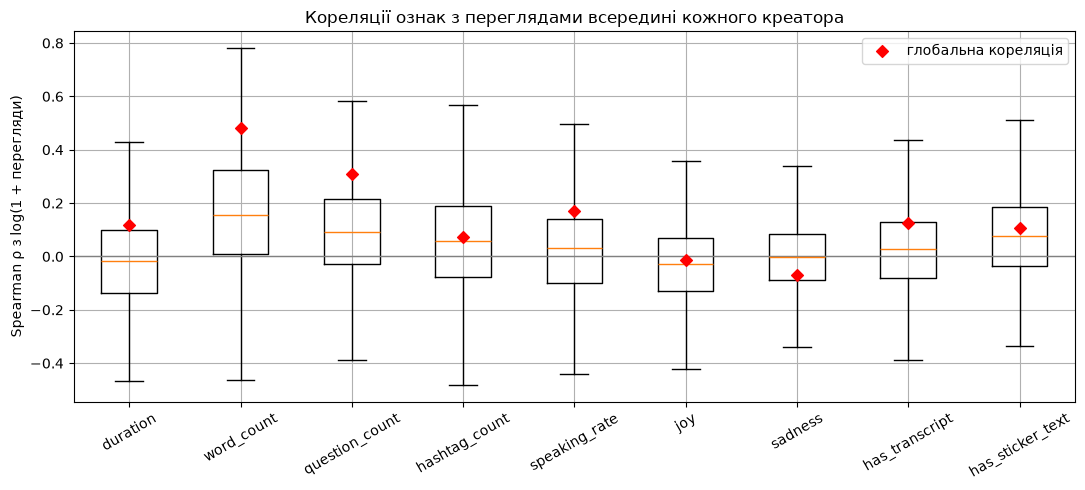

In [32]:
FEATS_PLOT = ["duration", "word_count", "question_count", "hashtag_count", "speaking_rate", "joy", "sadness", "has_transcript", "has_sticker_text"]

fig, ax = plt.subplots(figsize=(11, 5))
ax.boxplot([real[f] for f in FEATS_PLOT], tick_labels=FEATS_PLOT, showfliers=False)
ax.scatter(range(1, len(FEATS_PLOT) + 1), summary.loc[FEATS_PLOT, "глобальна"],
           color="red", marker="D", zorder=3, label="глобальна кореляція")
ax.axhline(0, color="grey", lw=1)
ax.set_ylabel("Spearman ρ з log(1 + перегляди)")
ax.set_title("Кореляції ознак з переглядами всередині кожного креатора")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Audience size as a confounder

Big accounts get more views regardless of content. We attach the follower count at the posting date (nearest observation in `creator_daily`) and check how strong this relation is.

**Result:**
- Spearman(followers, log views) = **0.64** — a strong relation.
- Accounts range from ~1k to ~30M followers; the dataset seems to include only accounts with at least ~1k followers.
- So a fair global baseline must get `follower_count` as a feature. A per-creator model controls for audience size automatically.
- Note: here we used the *nearest* date, which can be after posting. For modeling we must use the last value *before* posting to avoid data leakage.

Частка відео з даними про фоловерів: 1.0
Spearman(followers, log_views): 0.64


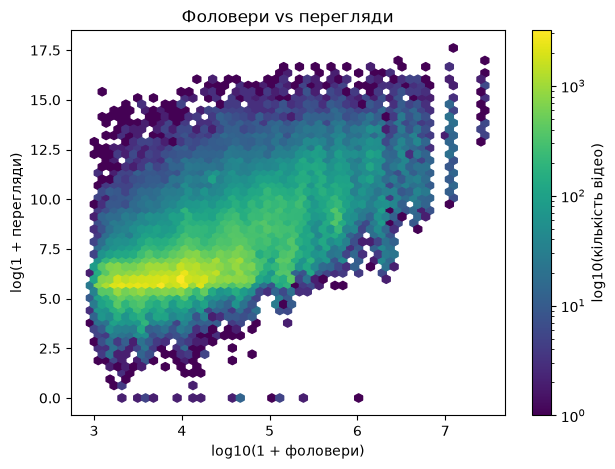

In [24]:
cr = creators.dropna(subset=["follower_count"]).copy()
cr["date"] = pd.to_datetime(cr["date"]).astype("datetime64[ns]")
cr = cr.sort_values("date")[["author_id", "date", "follower_count"]].rename(columns={"author_id": AUTHOR})

fol = pd.merge_asof(
    df[["video_id", AUTHOR, "create_date"]].sort_values("create_date"),
    cr, left_on="create_date", right_on="date", by=AUTHOR, direction="nearest",
)
df = df.merge(fol[["video_id", "follower_count"]], on="video_id", how="left")
print("Частка відео з даними про фоловерів:", round(df["follower_count"].notna().mean(), 3))
print("Spearman(followers, log_views):", round(df["follower_count"].corr(df["log_views"], method="spearman"), 3))

d = df.dropna(subset=["follower_count"])
fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(np.log10(d["follower_count"] + 1), d["log_views"], gridsize=50, bins="log", cmap="viridis")
ax.set_xlabel("log10(1 + фоловери)")
ax.set_ylabel("log(1 + перегляди)")
ax.set_title("Фоловери vs перегляди")
ax.grid(False)
fig.colorbar(hb, label="log10(кількість відео)")
plt.show()

## 11. Save intermediate data

We save the videos with the target to `data/interim/` (as described in `data/README.md`) and a copy to Drive, because `/content` is wiped after the session. The next notebook (Feature Engineering) starts from this file. Data files are not committed to git.

**Result:** `data/interim/videos_with_target.parquet` — 209,543 rows, 51 columns.

In [25]:
OUT = Path("data/interim/videos_with_target.parquet")
OUT.parent.mkdir(parents=True, exist_ok=True)
df.to_parquet(OUT, index=False)
shutil.copy(OUT, DRIVE_DATA / OUT.name)
print(OUT, df.shape)

data/interim/videos_with_target.parquet (209543, 51)


## Conclusions

1. **Data.** 209,543 videos from 1,872 creators (Jun–Nov 2024), all linked to daily engagement and account stats. Text statistics are missing for 38% of videos; emotions are almost complete.
2. **Enough data per creator.** Median 69 videos per creator. With `min_videos_per_creator = 30` we keep 1,439 creators and 96% of videos — we keep this value.
3. **Target.** `log(1 + views)` at day ~30 (last observation ≤ day 30). Raw views are too skewed. Engagement rate is a possible second target: it measures a different thing (correlation with log views −0.11).
4. **The creator dominates.** The author alone explains 74% of the variance in log views; follower count correlates at 0.64. A global model will mostly learn "who is the author" unless we give it creator features.
5. **Personalization is supported.** Inside creators, feature effects vary more than noise for all 14 features, and global correlations are inflated by between-creator differences (e.g., `word_count` 0.48 vs 0.16; `duration` has the opposite sign for 54% of creators). So global explanations can be misleading for individual creators. Effects per feature are modest, so the gain in accuracy still has to be shown by the models.

**Next steps**
- **Feature Engineering** (`02-...`, code in `src/creator_analytics/features.py`): followers *before* posting, creator's average views on *previous* videos, one-hot `topic` and `music_selected_from`, cyclic hour, flags for missing transcript/text stats/emotions. Avoid leakage: no likes/comments/shares as features.
- **Baselines:** (1) global model without creator features, (2) global model with creator features, then (3) per-creator models.
- Update the "TODO (after EDA)" sections in `data/README.md` with these numbers.